# LAB 02 — N-gram Language Models, Smoothing and Perplexity (experiments)

**Corpus:** 20 000 abstract bài báo Machine Learning trên arXiv (`CShorten/ML-ArXiv-Papers`, cùng nguồn với LAB 01, lấy mẫu seed 42). Chia theo **document**: train 80% / validation 10% / test 10%.

**Preprocessing** (`ngram_lm.tokenize`): tách câu theo `. ! ?`, lowercase, công thức `$...$` và số → `<num>`, bỏ dấu câu. Vocabulary = từ xuất hiện ≥ 2 lần trong train, còn lại → `<unk>`. Mọi model dùng **cùng** preprocessing, vocabulary và tập token được dự đoán (từ + `</s>`) nên perplexity so sánh được.

In [1]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
import math, random, time, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from datasets import load_dataset
import ngram_lm as lmlib
from ngram_lm import NGramLanguageModel, BOS, EOS, UNK

SEED = 42
raw = load_dataset("CShorten/ML-ArXiv-Papers", split="train").to_pandas()[["title", "abstract"]].dropna()
for c in ["title", "abstract"]:
    raw[c] = raw[c].str.replace(r"\s+", " ", regex=True).str.strip()
raw = raw.drop_duplicates("title").drop_duplicates("abstract")
df = raw.sample(n=20000, random_state=SEED).reset_index(drop=True)
idx = np.random.RandomState(SEED).permutation(len(df))
splits = {"train": idx[:16000], "validation": idx[16000:18000], "test": idx[18000:]}

def to_sentences(texts):
    return [t for doc in texts for t in (lmlib.tokenize(s) for s in lmlib.split_sentences(doc)) if t]

sents_raw = {k: to_sentences(df.abstract.values[v]) for k, v in splits.items()}
vocab = lmlib.build_vocabulary(sents_raw["train"], min_count=2)
sents = {k: lmlib.replace_oov(v, vocab) for k, v in sents_raw.items()}
print("Ví dụ câu sau tokenize:", sents_raw["train"][0][:25])

Ví dụ câu sau tokenize: ['embedding', 'methods', 'which', 'enforce', 'a', 'partial', 'order', 'or', 'lattice', 'structure', 'over', 'the', 'concept', 'space', 'such', 'as', 'order', 'embeddings', 'oe', 'vendrov', 'et', 'al', '<num>', 'are', 'a']


## Experiment 1 — Corpus statistics

In [2]:
rows = []
for k, v in splits.items():
    toks = [w for s in sents_raw[k] for w in s]
    rows.append({"split": k, "documents": len(v), "sentences": len(sents_raw[k]), "tokens": len(toks),
                 "unique words (raw)": len(set(toks)), "OOV rate vs train vocab": np.mean([w not in vocab for w in toks])})
corpus_stats = pd.DataFrame(rows).set_index("split")
display(corpus_stats.round(4))
print(f"Vocabulary (min_count=2) = {len(vocab):,} từ (+ <unk>, </s>) | từ chỉ xuất hiện 1 lần trong train: "
      f"{corpus_stats.loc['train', 'unique words (raw)'] - len(vocab):,}")

ngram_counts = {n: lmlib.count_ngrams(sents["train"], n) for n in (1, 2, 3)}
ng_stats = pd.DataFrame([{"model": name, "# n-gram tokens": sum(c.values()), "# unique n-grams": len(c),
                          "# singletons (count = 1)": sum(1 for x in c.values() if x == 1),
                          "% singletons": sum(1 for x in c.values() if x == 1) / len(c)}
                         for name, c in zip(["Unigram", "Bigram", "Trigram"], ngram_counts.values())]).set_index("model")
display(ng_stats.style.format({"# n-gram tokens": "{:,}", "# unique n-grams": "{:,}", "# singletons (count = 1)": "{:,}", "% singletons": "{:.1%}"}))
for n, c in ngram_counts.items():
    print(f"Top-8 {n}-gram:", [(" ".join(g), f) for g, f in c.most_common(8)])

,documents,sentences,tokens,unique words (raw),OOV rate vs train vocab
split,,,,,
train,16000,114562,2675459,52209,0.0086
validation,2000,14253,333194,16406,0.0199
test,2000,14373,334430,16658,0.0206


Vocabulary (min_count=2) = 29,314 từ (+ <unk>, </s>) | từ chỉ xuất hiện 1 lần trong train: 22,895


,# n-gram tokens,# unique n-grams,# singletons (count = 1),% singletons
model,,,,
Unigram,"2,790,021","29,316",0,0.0%
Bigram,"2,790,021","651,846","443,320",68.0%
Trigram,"2,790,021","1,665,210","1,420,397",85.3%


Top-8 1-gram: [('the', 148293), ('</s>', 114562), ('of', 88726), ('and', 71631), ('to', 69024), ('a', 66696), ('in', 53533), ('we', 43262)]
Top-8 2-gram: [('<s> we', 19484), ('of the', 18483), ('<s> in', 12192), ('<s> the', 11975), ('in the', 9914), ('in this', 8002), ('to the', 6758), ('on the', 6692)]
Top-8 3-gram: [('<s> <s> we', 19484), ('<s> <s> in', 12192), ('<s> <s> the', 11975), ('<s> in this', 6793), ('<s> <s> this', 5759), ('<s> <s> our', 4872), ('in this paper', 4453), ('this paper we', 3927)]


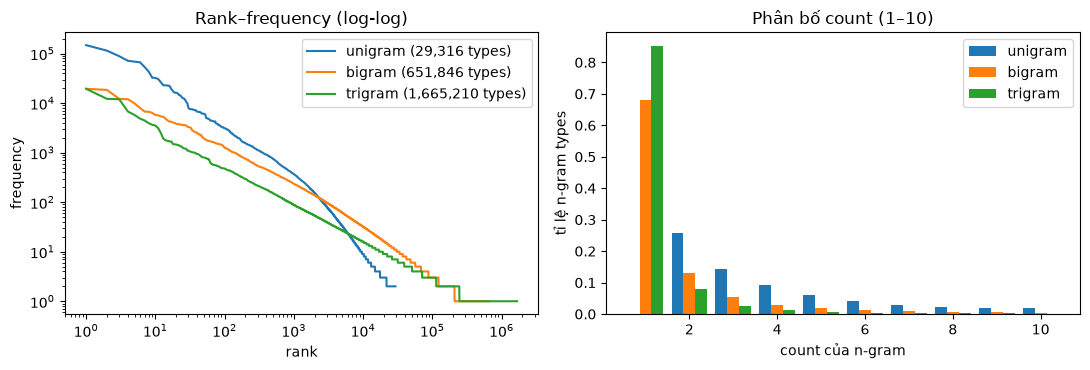

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for (n, c), name in zip(ngram_counts.items(), ["unigram", "bigram", "trigram"]):
    f = np.array(sorted(c.values(), reverse=True))
    ax[0].loglog(np.arange(1, len(f) + 1), f, label=f"{name} ({len(f):,} types)")
    vals, cnts = np.unique(f, return_counts=True)
    ax[1].bar(np.arange(1, 11) + (n - 2) * 0.27, [cnts[vals == i].sum() / len(f) for i in range(1, 11)], width=0.27, label=name)
ax[0].set_xlabel("rank"); ax[0].set_ylabel("frequency"); ax[0].set_title("Rank–frequency (log-log)"); ax[0].legend()
ax[1].set_xlabel("count của n-gram"); ax[1].set_ylabel("tỉ lệ n-gram types"); ax[1].set_title("Phân bố count (1–10)"); ax[1].legend()
plt.tight_layout(); plt.savefig("ngram_frequency.png", dpi=150); plt.show()

## Core implementation — unit tests và kiểm chứng bài tính tay

In [4]:
lmlib.run_tests()
toy = [s.split() for s in ["the cat eats fish", "the cat likes fish", "the dog eats meat"]]
uni = Counter(w for s in toy for w in s); N = sum(uni.values())
print(f"\nBài 1: V = {len(uni)}, N = {N}; P(the) = {uni['the']/N:.4f}, P(cat) = {uni['cat']/N:.4f}, P(fish) = {uni['fish']/N:.4f}, P(dog) = {uni['dog']/N:.4f}; Σ = {sum(uni.values())/N}")
bi = NGramLanguageModel(2, "mle").fit(toy)
print("Bài 2: P(cat|the) = %.4f, P(dog|the) = %.4f, P(eats|cat) = %.4f, P(likes|cat) = %.4f" % tuple(
    bi.probability([h], w) for h, w in [("the", "cat"), ("the", "dog"), ("cat", "eats"), ("cat", "likes")]))
p_fish_eats = bi.probability(["eats"], "fish"); p_eats_dog = bi.probability(["dog"], "eats")
print(f"Bài 3: P(the)·P(cat|the)·P(eats|cat)·P(fish|eats) = {0.25 * 2/3 * 0.5 * p_fish_eats:.4f} (= 1/24)")
print(f"Bài 4: S1 = {0.25 * 2/3 * 0.5 * p_fish_eats:.4f}, S2 = P(the)·P(dog|the)·P(eats|dog)·P(fish|eats) = {0.25 * 1/3 * p_eats_dog * p_fish_eats:.4f}")
print("       Với <s>, </s> (model đầy đủ): P(S1) =", round(bi.sentence_probability("the cat eats fish".split()), 4),
      "| P(S2) =", round(bi.sentence_probability("the dog eats fish".split()), 4))
toy9 = [s.split() for s in ["I like NLP", "I like AI", "I study NLP"]]
b9 = NGramLanguageModel(2, "mle").fit(toy9)
print(f"Bài 9: C(study AI) = {b9.counts[2][('study', 'AI')]}, P_MLE(AI|study) = {b9.probability(['study'], 'AI')}, "
      f"log P('I study AI') = {b9.sentence_log_probability('I study AI'.split())}")
print(f"Bài 11: (0+1)/(10+5) = {1/15:.4f}; (3+1)/(10+5) = {4/15:.4f} (MLE = {3/10})")
for p2 in (0.25, 0.1):
    P = 0.5 * p2 * 0.5
    print(f"Bài 18: P(w2|w1) = {p2}: P(S) = {P:.4f}, PP = P^(-1/3) = {P ** (-1/3):.4f}")

PASS  test_counts_and_unigram
PASS  test_bigram_mle
PASS  test_sentence_probability_and_log
PASS  test_laplace
PASS  test_interpolation_and_perplexity
5/5 tests passed

Bài 1: V = 7, N = 12; P(the) = 0.2500, P(cat) = 0.1667, P(fish) = 0.1667, P(dog) = 0.0833; Σ = 1.0
Bài 2: P(cat|the) = 0.6667, P(dog|the) = 0.3333, P(eats|cat) = 0.5000, P(likes|cat) = 0.5000
Bài 3: P(the)·P(cat|the)·P(eats|cat)·P(fish|eats) = 0.0417 (= 1/24)
Bài 4: S1 = 0.0417, S2 = P(the)·P(dog|the)·P(eats|dog)·P(fish|eats) = 0.0417
       Với <s>, </s> (model đầy đủ): P(S1) = 0.1667 | P(S2) = 0.1667
Bài 9: C(study AI) = 0, P_MLE(AI|study) = 0.0, log P('I study AI') = -inf
Bài 11: (0+1)/(10+5) = 0.0667; (3+1)/(10+5) = 0.2667 (MLE = 0.3)
Bài 18: P(w2|w1) = 0.25: P(S) = 0.0625, PP = P^(-1/3) = 2.5198
Bài 18: P(w2|w1) = 0.1: P(S) = 0.0250, PP = P^(-1/3) = 3.4200


### Vì sao cần log probability?
Xác suất của một abstract dài là tích của hàng trăm số < 1 → nhỏ hơn số float64 nhỏ nhất (≈ 1e-308) và bị làm tròn về 0.

In [5]:
probe = NGramLanguageModel(2, "laplace").fit(sents["train"])
long_doc = [w for s in sents["test"][:12] for w in s]
print(f"Chuỗi {len(long_doc)} token: tích xác suất = {probe.sentence_probability(long_doc)!r} (underflow)")
lp = probe.sentence_log_probability(long_doc)
print(f"log P = {lp:.1f}  →  P = 10^{lp / math.log(10):.0f}; float64 nhỏ nhất ≈ 1e-308")

Chuỗi 291 token: tích xác suất = 0.0 (underflow)
log P = -2242.6  →  P = 10^-974; float64 nhỏ nhất ≈ 1e-308


## Experiment 2 — MLE vs smoothing (Laplace, add-k, interpolation)
add-k: chọn k trên **validation**; interpolation: chọn λ trên **validation** (lưới bước 0.1). Test chỉ dùng để báo cáo.

In [6]:
def fit(n, smoothing, **kw):
    return NGramLanguageModel(n, smoothing, **kw).fit(sents["train"])

t0 = time.time()
models = {(n, s): fit(n, s) for n in (1, 2, 3) for s in ("mle", "laplace")}
print(f"Train 6 model: {time.time() - t0:.1f}s")

k_grid = [1, 0.1, 0.03, 0.01, 0.003, 0.001]
best_k = {}
for n in (2, 3):
    m = models[(n, "laplace")]
    scores = {}
    for k in k_grid:
        m.smoothing, m.k = "addk", k
        scores[k] = m.perplexity(sents["validation"])
    m.smoothing, m.k = "laplace", 1.0
    best_k[n] = min(scores, key=scores.get)
    print(f"{n}-gram add-k, validation PPL theo k:", {k: round(v, 1) for k, v in scores.items()}, "→ k* =", best_k[n])
    models[(n, "addk")] = fit(n, "addk", k=best_k[n])

best_lam = {}
for n in (2, 3):
    m = fit(n, "interp")
    grid = [l for l in itertools.product(np.arange(0.1, 1.0, 0.1), repeat=n - 1) if sum(l) < 1 - 1e-9]
    scores = {}
    for l in grid:
        m.lambdas = [round(1 - sum(l), 2)] + [round(x, 2) for x in l]
        scores[tuple(m.lambdas)] = m.perplexity(sents["validation"])
    best_lam[n] = min(scores, key=scores.get)
    m.lambdas = list(best_lam[n]); models[(n, "interp")] = m
    print(f"{n}-gram interpolation: λ* (uni, bi, tri) = {best_lam[n]}, validation PPL = {scores[best_lam[n]]:.1f}")

Train 6 model: 35.5s


2-gram add-k, validation PPL theo k: {1: 1207.8, 0.1: 465.2, 0.03: 347.3, 0.01: 304.0, 0.003: 297.6, 0.001: 317.1} → k* = 0.003


3-gram add-k, validation PPL theo k: {1: 7186.3, 0.1: 3120.4, 0.03: 2133.4, 0.01: 1637.2, 0.003: 1379.9, 0.001: 1334.4} → k* = 0.001


2-gram interpolation: λ* (uni, bi, tri) = (np.float64(0.2), np.float64(0.8)), validation PPL = 226.0


3-gram interpolation: λ* (uni, bi, tri) = (np.float64(0.2), np.float64(0.5), np.float64(0.3)), validation PPL = 191.4


In [7]:
NAMES = {1: "Unigram", 2: "Bigram", 3: "Trigram"}
SM = {"mle": "MLE", "laplace": "Laplace", "addk": "Add-k", "interp": "Interpolation"}
rows = []
for (n, s), m in models.items():
    r = {"model": f"{NAMES[n]} {SM[s]}", "n": n, "smoothing": SM[s], "k / λ": m.k if s == "addk" else (best_lam.get(n) if s == "interp" else "")}
    for split in ("train", "validation", "test"):
        ppl, ntok, nz = m.evaluate(sents[split])
        r[f"{split} PPL"] = ppl; r[f"{split} % P=0"] = nz / ntok
    rows.append(r)
ppl_table = pd.DataFrame(rows).sort_values(["n", "smoothing"]).reset_index(drop=True)
display(ppl_table.round(4))

,model,n,smoothing,k / λ,train PPL,train % P=0,validation PPL,validation % P=0,test PPL,test % P=0
0,Unigram Laplace,1,Laplace,,910.6756,0.0,833.5162,0.0000,830.4094,0.0000
1,Unigram MLE,1,MLE,,909.7951,0.0,830.7665,0.0000,827.6933,0.0000
2,Bigram Add-k,2,Add-k,0.003,110.3281,0.0,297.5791,0.0000,290.5347,0.0000
3,Bigram Interpolation,2,Interpolation,"(0.2, 0.8)",99.4439,0.0,226.0098,0.0000,221.0642,0.0000
4,Bigram Laplace,2,Laplace,,1073.3382,0.0,1207.8043,0.0000,1187.6119,0.0000
5,Bigram MLE,2,MLE,,86.2515,0.0,inf,0.1566,inf,0.1547
6,Trigram Add-k,3,Add-k,0.001,35.9690,0.0,1334.4063,0.0000,1307.1221,0.0000
7,Trigram Interpolation,3,Interpolation,"(0.2, 0.5, 0.3)",23.0741,0.0,191.3706,0.0000,187.2928,0.0000
8,Trigram Laplace,3,Laplace,,4759.9341,0.0,7186.2624,0.0000,7069.6055,0.0000
9,Trigram MLE,3,MLE,,10.8977,0.0,inf,0.5081,inf,0.5062


## Experiment 3 — Perplexity: Unigram vs Bigram vs Trigram + unseen n-grams (context length)

In [8]:
def unseen_rate(n, split):
    tr = ngram_counts[n]
    grams = [g for g, c in lmlib.count_ngrams(sents[split], n).items() for _ in range(c)]
    return np.mean([g not in tr for g in grams])

ctx = []
for n in (1, 2, 3):
    ctx.append({"model": NAMES[n], "# unique n-grams (train)": len(ngram_counts[n]),
                "% unseen n-gram tokens (val)": unseen_rate(n, "validation"), "% unseen n-gram tokens (test)": unseen_rate(n, "test"),
                "train PPL MLE": models[(n, "mle")].perplexity(sents["train"]),
                "val PPL best smoothing": min(models[(n, s)].perplexity(sents["validation"]) for s in ("laplace", "addk", "interp") if (n, s) in models),
                "test PPL best smoothing": min(models[(n, s)].perplexity(sents["test"]) for s in ("laplace", "addk", "interp") if (n, s) in models)})
context_table = pd.DataFrame(ctx).set_index("model")
display(context_table.round(4))

,# unique n-grams (train),% unseen n-gram tokens (val),% unseen n-gram tokens (test),train PPL MLE,val PPL best smoothing,test PPL best smoothing
model,,,,,,
Unigram,29316,0.0000,0.0000,909.7951,833.5162,830.4094
Bigram,651846,0.1566,0.1547,86.2515,226.0098,221.0642
Trigram,1665210,0.5081,0.5062,10.8977,191.3706,187.2928


### Tác động của corpus size
Train trên 10% / 25% / 50% / 100% train set (cùng vocabulary V), đánh giá validation. Dùng add-k (k* ở trên) và interpolation (λ* ở trên); "train PPL" đo trên 20 000 câu đầu của chính tập train con.

train fraction,0.10,0.25,0.50,1.00
model,,,,
Bigram add-k,724.3,475.6,366.9,297.6
Bigram interp,365.4,291.1,253.3,226.0
Trigram add-k,4486.5,2805.8,1933.6,1334.4
Trigram interp,331.0,258.8,220.4,191.4
Unigram Laplace,884.1,850.0,839.1,833.5


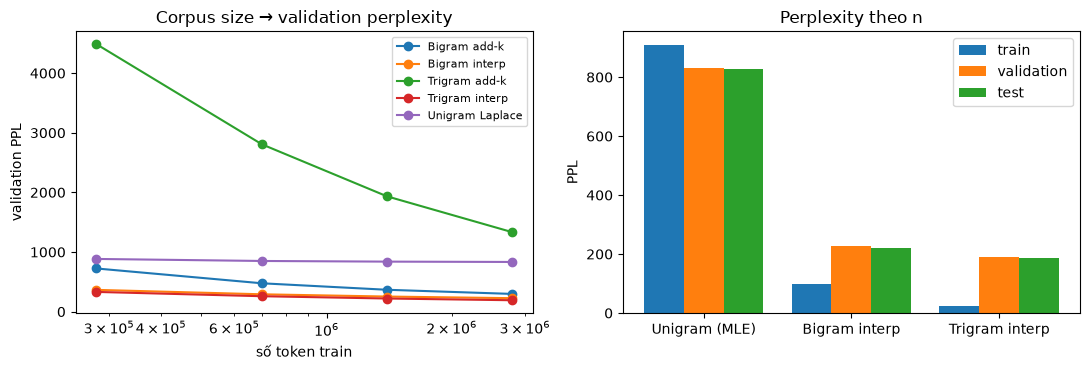

In [9]:
size_rows = []
rng = random.Random(SEED)
order = list(range(len(sents["train"]))); rng.shuffle(order)
full_vocab, full_V = models[(1, "mle")].vocab, models[(1, "mle")].V
configs = [("Unigram Laplace", 1, "laplace", {}), ("Bigram add-k", 2, "addk", {"k": best_k[2]}), ("Trigram add-k", 3, "addk", {"k": best_k[3]}),
           ("Bigram interp", 2, "interp", {"lambdas": list(best_lam[2])}), ("Trigram interp", 3, "interp", {"lambdas": list(best_lam[3])})]
for frac in (0.1, 0.25, 0.5, 1.0):
    sub = [sents["train"][i] for i in order[:int(frac * len(order))]]
    for name, n, sm, kw in configs:
        m = NGramLanguageModel(n, sm, **kw).fit(sub)
        m.vocab, m.V = full_vocab, full_V            # cùng V cho mọi kích thước → PPL so sánh được
        size_rows.append({"train fraction": frac, "train tokens": sum(len(x) + 1 for x in sub), "model": name,
                          "train PPL": m.perplexity(sub[:20000]), "val PPL": m.perplexity(sents["validation"])})
size_table = pd.DataFrame(size_rows)
display(size_table.pivot(index="model", columns="train fraction", values="val PPL").round(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, g in size_table.groupby("model"):
    ax[0].plot(g["train tokens"], g["val PPL"], marker="o", label=name)
ax[0].set_xscale("log"); ax[0].set_xlabel("số token train"); ax[0].set_ylabel("validation PPL"); ax[0].set_title("Corpus size → validation perplexity"); ax[0].legend(fontsize=8)
x = np.arange(3)
for i, split in enumerate(["train", "validation", "test"]):
    vals = [models[(n, "interp")].perplexity(sents[split]) if n > 1 else models[(1, "mle")].perplexity(sents[split]) for n in (1, 2, 3)]
    ax[1].bar(x + (i - 1) * 0.27, vals, width=0.27, label=split)
ax[1].set_xticks(x, ["Unigram (MLE)", "Bigram interp", "Trigram interp"]); ax[1].set_ylabel("PPL"); ax[1].set_title("Perplexity theo n"); ax[1].legend()
plt.tight_layout(); plt.savefig("perplexity.png", dpi=150); plt.show()

## Application 1 — Next-word prediction
Model: trigram interpolation (λ*). Context lấy từ các câu thật trong **test set**, kèm từ thật đứng sau.

In [10]:
lm = models[(3, "interp")]

def find_actual(context, split="test"):
    c = context.split()
    for s in sents[split]:
        for i in range(len(s) - len(c)):
            if s[i:i + len(c)] == c:
                return s[i + len(c)]
    return None

contexts = ["the cat", "natural language", "machine learning", "neural networks", "in this paper we", "reinforcement learning",
            "state of the", "we propose a novel", "experimental results", "support vector"]
nw_rows = []
for c in contexts:
    top = lm.next_word_distribution(c.split(), top_k=5)
    actual = find_actual(c)
    rank = next((r for r, (w, _) in enumerate(top, 1) if w == actual), None)
    nw_rows.append({"context": c, "top-5 prediction": ", ".join(f"{w} {p:.3f}" for w, p in top),
                    "actual next word (test)": actual or "—", "P(actual|context)": round(lm.probability(c.split(), actual), 4) if actual else None,
                    "actual in top-5": rank or "no"})
next_word = pd.DataFrame(nw_rows)
display(next_word)
print(f"'cat' trong vocabulary: {'cat' in vocab}; C(cat) = {lm.counts[1][('cat',)]}, C(the cat) = {lm.counts[2][('the', 'cat')]} "
      f"→ context 'the cat' gần như không có trong corpus ML (domain mismatch)")

,context,top-5 prediction,actual next word (test),P(actual|context),actual in top-5
0,the cat,"this 0.329, is 0.058, and 0.033, to 0.033, whi...",—,NaN,no
1,natural language,"processing 0.255, models 0.077, </s> 0.050, mo...",processing,0.2554,1
2,machine learning,"</s> 0.067, models 0.055, and 0.045, algorithm...",applications,0.0092,no
3,neural networks,"</s> 0.132, and 0.051, are 0.040, with 0.039, ...",with,0.0393,4
4,in this paper we,"propose 0.157, present 0.058, show 0.049, intr...",propose,0.1574,1
5,reinforcement learning,"</s> 0.074, rl 0.066, and 0.036, algorithms 0....",approach,0.0115,no
6,state of the,"proposed 0.028, data 0.013, <unk> 0.013, model...",art,0.0081,no
7,we propose a novel,"approach 0.044, method 0.041, framework 0.027,...",dialogue,0.0003,no
8,experimental results,"show 0.160, on 0.118, demonstrate 0.070, in 0....",show,0.1598,1
9,support vector,"machine 0.230, machines 0.157, </s> 0.039, reg...",machine,0.2296,1


'cat' trong vocabulary: True; C(cat) = 18, C(the cat) = 1 → context 'the cat' gần như không có trong corpus ML (domain mismatch)


In [11]:
# Đánh giá định lượng: top-1 / top-5 accuracy trên 3 000 vị trí ngẫu nhiên trong test (bỏ vị trí đầu câu)
rng = random.Random(1)
positions = [(s, rng.randrange(2, len(s))) for s in rng.sample([s for s in sents["test"] if len(s) > 2], 3000)]
acc_rows = []
for name, m in [("Unigram MLE", models[(1, "mle")]), ("Bigram interp", models[(2, "interp")]), ("Trigram interp", models[(3, "interp")]),
                ("Trigram Laplace", models[(3, "laplace")])]:
    t0 = time.time(); hit1 = hit5 = 0
    for s, i in positions:
        top = [w for w, _ in m.next_word_distribution(s[:i], top_k=5)]
        hit1 += top[0] == s[i]; hit5 += s[i] in top
    acc_rows.append({"model": name, "top-1 acc": hit1 / len(positions), "top-5 acc": hit5 / len(positions), "time (s)": time.time() - t0})
nw_acc = pd.DataFrame(acc_rows).set_index("model")
display(nw_acc.round(4))

,top-1 acc,top-5 acc,time (s)
model,,,
Unigram MLE,0.0503,0.1373,4.6011
Bigram interp,0.1637,0.3470,25.6720
Trigram interp,0.1950,0.3740,34.5369
Trigram Laplace,0.1770,0.2967,10.5009


## Application 2 — Sentence ranking
Điểm = log P(continuation | context) (trigram interpolation, có `</s>`). Cột "per token" = log-prob trung bình mỗi token để so các câu khác độ dài.

In [12]:
def score_continuation(context, cont, m=lm):
    c, x = context.split(), [w if w in vocab else UNK for w in cont.split()]
    full = [BOS] * (m.n - 1) + c + x + [EOS]
    lp = sum(math.log(m.probability(full[i - m.n + 1:i], full[i])) for i in range(m.n - 1 + len(c), len(full)))
    return lp, lp / (len(x) + 1)

ranking_sets = {
    "machine learning": ["is useful for nlp", "banana computer quickly", "studies language models"],
    "in this paper we": ["propose a novel method", "method novel a propose", "eat a delicious pizza"],
    "the proposed model": ["outperforms the baseline", "baseline the outperforms", "outperforms the banana"],
}
rank_rows = []
for ctx_, cands in ranking_sets.items():
    scored = sorted(((score_continuation(ctx_, c), c) for c in cands), reverse=True)
    for r, ((lp, per), c) in enumerate(scored, 1):
        rank_rows.append({"context": ctx_, "rank": r, "candidate": c, "log P": round(lp, 2), "log P / token": round(per, 2)})
display(pd.DataFrame(rank_rows))

,context,rank,candidate,log P,log P / token
0,machine learning,1,studies language models,-21.04,-5.26
1,machine learning,2,is useful for nlp,-22.90,-4.58
2,machine learning,3,banana computer quickly,-38.32,-9.58
3,in this paper we,1,propose a novel method,-11.36,-2.27
4,in this paper we,2,eat a delicious pizza,-30.06,-6.01
5,in this paper we,3,method novel a propose,-32.81,-6.56
6,the proposed model,1,outperforms the baseline,-11.64,-2.91
7,the proposed model,2,outperforms the banana,-24.75,-6.19
8,the proposed model,3,baseline the outperforms,-27.03,-6.76


## Error analysis — next-word prediction
Lấy 2 dự đoán đúng và 2 dự đoán sai (top-1) từ các vị trí test ở trên, kèm count của context trong train.

In [13]:
tri = lm
def describe(s, i):
    h = tuple(s[max(0, i - 2):i]); top = tri.next_word_distribution(list(h), top_k=3)
    c_ctx = tri.context_counts[3][((BOS,) * (2 - len(h)) + h)]
    return {"context": " ".join(h), "model prediction": top[0][0], "P(pred)": round(top[0][1], 3), "expected": s[i],
            "P(expected)": round(tri.probability(list(h), s[i]), 4), "C(context) train": c_ctx,
            "C(context, expected) train": tri.counts[3][((BOS,) * (2 - len(h)) + h) + (s[i],)], "sentence": " ".join(s[max(0, i - 6):i + 3])}

cases = [describe(s, i) for s, i in positions[:400]]
cases = pd.DataFrame(cases)
correct = cases[cases["model prediction"] == cases["expected"]]
wrong = cases[cases["model prediction"] != cases["expected"]]
display(correct.sort_values("C(context) train", ascending=False).head(6))
display(wrong.head(12))

,context,model prediction,P(pred),expected,P(expected),C(context) train,"C(context, expected) train",sentence
91,of the,proposed,0.028,proposed,0.0276,18483,883,demonstrate the superior performance of the pr...
112,in this,paper,0.306,paper,0.3060,8002,4453,the first contribution in this paper is of
173,we propose,a,0.440,a,0.4401,5675,3109,we propose a smoothing technique
83,we propose,a,0.440,a,0.4401,5675,3109,we propose a spliced <unk>
225,due to,the,0.193,the,0.1928,1803,801,due to the large scale
56,is the,first,0.061,first,0.0610,1732,322,of our knowledge this is the first application of


,context,model prediction,P(pred),expected,P(expected),C(context) train,"C(context, expected) train",sentence
2,such as,a,0.104,amazon,0.0001,3705,1,by many online retailers such as amazon
3,positioning iii,the,0.084,boundary,0.0000,0,0,equivalence partitioning ii centroid positioni...
4,datasets <unk>,and,0.180,is,0.0072,19,0,on both datasets <unk> is superior wrt
7,are used,to,0.331,in,0.1295,391,47,the first time <unk> are used in machine learning
8,it is,a,0.066,the,0.0410,2258,28,it is the one-pass learning
9,the corresponding,to,0.119,examples,0.0001,262,0,difference between outcomes of the correspondi...
10,recognition task,</s>,0.167,with,0.0341,27,2,examined the zero-shot activity recognition ta...
11,the arms,</s>,0.160,are,0.1342,32,8,only been obtained when the arms are gaussian ...
12,depends on,the,0.328,it,0.0010,232,0,human computer interaction strongly depends on it
13,for solving,the,0.171,different,0.0051,229,2,nowadays a popular framework for solving diffe...


In [14]:
results = []
for _, r in ppl_table.iterrows():
    for split in ("train", "validation", "test"):
        results.append({"experiment": "perplexity", "model": r.model, "split": split, "metric": "PPL", "value": r[f"{split} PPL"]})
        results.append({"experiment": "perplexity", "model": r.model, "split": split, "metric": "% tokens P=0", "value": r[f"{split} % P=0"]})
for _, r in size_table.iterrows():
    results.append({"experiment": f"corpus size {r['train fraction']:.0%}", "model": r.model, "split": "validation", "metric": "PPL", "value": r["val PPL"]})
for name, r in nw_acc.iterrows():
    for met in ("top-1 acc", "top-5 acc"):
        results.append({"experiment": "next-word prediction", "model": name, "split": "test", "metric": met, "value": r[met]})
for _, r in next_word.iterrows():
    results.append({"experiment": "next-word example", "model": "Trigram interp", "split": "test", "metric": f"context='{r.context}' actual='{r['actual next word (test)']}' top5='{r['top-5 prediction']}'", "value": r["P(actual|context)"]})
pd.DataFrame(results).to_csv("results.csv", index=False)
print("Đã ghi results.csv:", len(results), "dòng")

Đã ghi results.csv: 98 dòng
